# Geração de runs sintéticas com K-means — FOG / Whirlpool (G03)

**O que este notebook faz.** Agrupa as 56 runs reais por assinatura térmica usando K-means, aprende o
mapeamento entre os 7 fatores de projeto e o cluster, sorteia 44 configurações de hardware inéditas e
gera o perfil térmico de cada uma interpolando runs reais do cluster previsto. Resultado: **100 runs**
(56 reais + 44 sintéticas).

**O que este notebook não faz: fingir que isso cria informação nova.**

O `diagnostico_dados_e_validacao.ipynb` mediu o piso irredutível de erro deste dataset em **7,41 °C**,
contra um RMSE honesto de **8,08 °C** — 8% de margem. Esse piso vem de runs com features idênticas que
produziram temperaturas diferentes: o gargalo é variável não medida, não número de amostras. Uma run
sintética construída a partir dos mesmos 7 fatores herda exatamente essa limitação, e seu rótulo sai do
próprio modelo — é circular por construção.

Então o entregável honesto não é o CSV: é **o experimento**. Geramos, medimos com ablação (treinar com e
sem sintético, testando sempre e somente em dado real) e reportamos o que deu — inclusive se piorar.
O veredito está na seção 9.

**Dois pontos onde este notebook pára e admite falha em vez de seguir:**

1. Se os fatores não predisserem o cluster melhor que chutar a classe majoritária (seção 3), o `assert`
   quebra. Sem esse mapeamento, toda run sintética seria rotulada ao acaso.
2. Se os `assert` de contrato do arquivo (seção 8) falharem, nada é gravado.

**Arquivos gerados.** `dataset_preprocessado.csv` **não é alterado** — sem um conjunto puramente real a
ablação da seção 7 deixa de ser possível.

| Arquivo | Conteúdo |
|---|---|
| `data/dataset_sintetico.csv` | só as 44 runs sintéticas |
| `data/dataset_com_sinteticos.csv` | as 100 runs (56 reais + 44 sintéticas) |
| `data/sintetico_rastreabilidade.csv` | de quais runs-mãe cada sintética saiu, com λ e cluster |


In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import silhouette_score, mean_absolute_error, r2_score
from sklearn.model_selection import GroupKFold, LeaveOneOut, cross_val_predict

RANDOM_STATE   = 0
N_SINTETICAS   = 44          # 56 reais + 44 = 100 runs
SIGMA_RUIDO    = 2.18        # desvio mediano entre replicas reais (secao 5 do diagnostico)
LAMBDA_MIN, LAMBDA_MAX = 0.2, 0.8
N_TREES        = 150

FATORES = ['blower_direction', 'housing', 'board_position', 'run_case',
           'losses', 'deflector_hole', 'material_coil_support']
ALVO, GRUPO = 'temp', 'run_id'

rng = np.random.default_rng(RANDOM_STATE)

df = pd.read_csv('../data/dataset_preprocessado.csv')
df.columns = [c.strip().replace('\ufeff', '') for c in df.columns]

print('reais  : %d runs, %d linhas, %d TCs' % (df[GRUPO].nunique(), len(df), df['tc_number'].nunique()))

# Propriedades do termopar (nao da run) - herdadas pelas runs sinteticas.
TC_INFO = df.groupby('tc_number')[['tc_name', 'key_area', 'active_limit']].first()
assert df.groupby('tc_number')[['tc_name', 'key_area', 'active_limit']].nunique().max().max() == 1, \
    'tc_number nao determina as propriedades do termopar'

fatores_por_run = df.groupby(GRUPO)[FATORES].first()
combo_real = fatores_por_run.astype(str).agg(' | '.join, axis=1)
COMBOS_REAIS = set(combo_real)
print('combos distintos reais: %d' % len(COMBOS_REAIS))

reais  : 56 runs, 4065 linhas, 77 TCs
combos distintos reais: 33


## 1. Matriz de assinatura térmica (56 runs × 77 TCs)

Cada run vira um vetor: uma temperatura por termopar. É esse vetor que o K-means agrupa — a hipótese é
que runs com perfil térmico parecido pertencem ao mesmo regime.

Duas decisões nesta célula:

- **Os 5,7% de células faltantes** (nem toda run mediu todos os 77 TCs) são preenchidos com a mediana do
  TC. Essa imputação serve **só** para o K-means. A geração do perfil na seção 5 volta a usar a matriz
  crua e respeita os faltantes — não se inventa medição onde ninguém mediu.
- **O z-score por TC é obrigatório.** Sem ele a distância euclidiana é dominada pelos termopares que
  chegam a 270 °C, e os que ficam em 30 °C não pesam nada. O K-means agruparia por "quem tem termopar
  quente" em vez de por regime térmico.


In [2]:
# ---- 1. Matriz de assinatura termica (56 runs x 77 TCs) ----
piv = df.pivot_table(index=GRUPO, columns='tc_number', values=ALVO, aggfunc='mean')
faltantes = piv.isna()

# Imputacao pela mediana do TC. Usada SOMENTE para o K-means:
# a geracao do perfil (secao 5) volta a usar `piv` cru e respeita os faltantes.
piv_imp = piv.fillna(piv.median())

# z-score por TC. Sem isso a distancia euclidiana e dominada pelos TCs de ~270 C
# e o K-means agruparia por "quem tem termopar quente", nao por regime termico.
desvio = piv_imp.std().replace(0, 1.0)
Z = (piv_imp - piv_imp.mean()) / desvio

print('matriz: %d runs x %d TCs | celulas faltantes: %d (%.1f%%)'
      % (piv.shape[0], piv.shape[1], int(faltantes.sum().sum()), 100 * faltantes.to_numpy().mean()))
print('TCs presentes nas 56 runs: %d' % int((~faltantes).sum().eq(56).sum()))

matriz: 56 runs x 77 TCs | celulas faltantes: 247 (5.7%)
TCs presentes nas 56 runs: 36


## 2. Ajuste do K-means para cada k candidato

Ainda não escolhemos `k` — só ajustamos todos os candidatos de 2 a 10 e registramos silhueta, inércia e
tamanho dos clusters. A escolha vem na seção 3, com o critério explicado lá.

Repare na coluna `tamanhos`: nenhum `k` produz clusters equilibrados. Isso não é defeito do algoritmo, é
propriedade dos dados — há um bloco grande de runs Broil e um punhado de Pyro, que é um modo de cocção
bem mais quente e se separa primeiro.


In [3]:
# ---- 2. Ajuste do K-means para cada k candidato ----
modelos, ajuste = {}, []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=25, random_state=RANDOM_STATE).fit(Z)
    tam = np.bincount(km.labels_)
    modelos[k] = km
    ajuste.append({'k': k, 'silhueta': silhouette_score(Z, km.labels_), 'inercia': km.inertia_,
                   'menor_cluster': int(tam.min()), 'tamanhos': tam.tolist()})

ajuste_df = pd.DataFrame(ajuste).set_index('k').round(3)
print(ajuste_df.to_string())

    silhueta   inercia  menor_cluster                          tamanhos
k                                                                      
2      0.459  3207.034              6                           [6, 50]
3      0.334  2617.147              5                        [5, 8, 43]
4      0.370  2164.465              2                     [4, 7, 43, 2]
5      0.266  1751.575              2                 [34, 4, 2, 14, 2]
6      0.269  1445.912              2             [10, 11, 4, 27, 2, 2]
7      0.310  1284.307              2            [2, 31, 4, 5, 2, 6, 6]
8      0.267  1132.321              2        [5, 22, 4, 2, 5, 10, 2, 6]
9      0.247  1038.838              1      [8, 22, 4, 2, 9, 5, 1, 4, 1]
10     0.243   933.553              1  [5, 9, 4, 1, 10, 5, 2, 1, 5, 14]


## 3. Mapeamento fatores → cluster: o gate do método

Para dar perfil térmico a uma configuração que nunca foi ensaiada, precisamos saber **em que cluster ela
cairia**. Isso é um classificador: 7 fatores → rótulo do cluster. Se ele não funcionar, toda run sintética
é rotulada ao acaso e o método inteiro desaba.

### Por que a silhueta é o critério errado aqui

A silhueta premia `k=2`, que separa 6 runs Pyro das outras 50. Só que nesse cenário um classificador
acerta 96% **chutando sempre a classe grande** — o baseline já é 89%. A métrica parece ótima e não
significa nada.

O que importa é o **ganho sobre o baseline de classe majoritária**: quanto o modelo acerta além do que
já vem de graça pelo desbalanceamento.

### Critério de escolha de k (fixado antes de olhar os resultados)

1. menor cluster ≥ 3 runs — abaixo disso não há pares variados para interpolar na seção 5;
2. entre os que passam, o **maior ganho sobre o baseline**.

A tabela mostra todos os `k` para o grupo poder discordar da escolha com os números à vista. Repare que
`k=7` e `k=8` têm ganho bem maior (0,357), mas caem no critério (1) com clusters de 2 runs. Se o grupo
quiser priorizar o ganho em vez da diversidade de pares, é só mudar `MIN_CLUSTER`.

O `assert` no fim é o gate.


In [4]:
# ---- 3. Mapeamento fatores -> cluster: o gate do metodo ----
# Se os 7 fatores nao predizem o cluster melhor que chutar a classe majoritaria, a run
# sintetica seria rotulada ao acaso e o metodo nao se sustenta. Note que ACURACIA ALTA
# NAO BASTA: com k=2 um cluster tem 50 das 56 runs, entao 0.89 de acerto vem de graca.
# O que vale e o GANHO sobre esse baseline.
#
# Criterio de escolha de k, fixado antes de olhar os resultados:
#   (a) menor cluster >= 3  -> precisa de pelo menos 3 runs para formar pares variados
#   (b) entre esses, o maior ganho sobre o baseline
from sklearn.model_selection import StratifiedKFold

MIN_CLUSTER = 3
Xf = pd.get_dummies(fatores_por_run.astype(str)).astype(float)

def skill_do_k(lab, n_trees=200, seed=RANDOM_STATE):
    tam = np.bincount(lab)
    cv = StratifiedKFold(n_splits=min(5, int(tam.min())), shuffle=True, random_state=seed)
    clf = RandomForestClassifier(n_estimators=n_trees, random_state=seed, n_jobs=-1)
    pred = cross_val_predict(clf, Xf.values, lab, cv=cv, n_jobs=1)
    return float((pred == lab).mean()), float(tam.max() / tam.sum())

scan = []
for k in range(2, 11):
    lab = modelos[k].labels_
    if np.bincount(lab).min() < 2:
        continue
    acc, base = skill_do_k(lab)
    pureza = pd.crosstab(lab, fatores_por_run['run_case'].values).max(axis=1).sum() / len(lab)
    scan.append({'k': k, 'silhueta': silhouette_score(Z, lab),
                 'menor_cluster': int(np.bincount(lab).min()), 'acuracia': acc,
                 'baseline': base, 'ganho': acc - base, 'pureza_run_case': pureza})

scan_df = pd.DataFrame(scan).set_index('k').round(3)
print(scan_df.to_string())

elegiveis = scan_df[scan_df['menor_cluster'] >= MIN_CLUSTER]
assert (elegiveis['ganho'] > 0).any(), 'GATE REPROVADO: nenhum k com ganho sobre o baseline'
K = int(elegiveis['ganho'].idxmax())
kmeans = modelos[K]
rotulo_cluster = pd.Series(kmeans.labels_, index=Z.index, name='cluster')

print('\nk escolhido: %d  (ganho %.3f = acuracia %.3f - baseline %.3f)'
      % (K, elegiveis.loc[K, 'ganho'], elegiveis.loc[K, 'acuracia'], elegiveis.loc[K, 'baseline']))
print('tamanhos:', np.bincount(rotulo_cluster).tolist())

# Confirmacao com LeaveOneOut (n=56) apenas para o k escolhido.
clf_final = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
pred_loo = cross_val_predict(clf_final, Xf.values, rotulo_cluster.values, cv=LeaveOneOut(), n_jobs=1)
acc_loo = float((pred_loo == rotulo_cluster.values).mean())
base_k = float(np.bincount(rotulo_cluster).max() / len(rotulo_cluster))
print('LeaveOneOut: acuracia %.3f vs baseline %.3f (ganho %.3f)' % (acc_loo, base_k, acc_loo - base_k))
assert acc_loo > base_k, 'GATE REPROVADO no LOO: o mapeamento fatores->cluster nao tem skill'

clf_final.fit(Xf.values, rotulo_cluster.values)

print('\n=== cluster x run_case (sanidade: os clusters refletem modo de coccao?) ===')
print(pd.crosstab(rotulo_cluster, fatores_por_run['run_case']).to_string())

   silhueta  menor_cluster  acuracia  baseline  ganho  pureza_run_case
k                                                                     
2     0.459              6     0.964     0.893  0.071            0.554
3     0.334              5     0.911     0.768  0.143            0.571
4     0.370              2     0.875     0.768  0.107            0.571
5     0.266              2     0.804     0.607  0.196            0.768
6     0.269              2     0.786     0.482  0.304            0.679
7     0.310              2     0.911     0.554  0.357            0.714
8     0.267              2     0.750     0.393  0.357            0.839

k escolhido: 3  (ganho 0.143 = acuracia 0.911 - baseline 0.768)
tamanhos: [5, 8, 43]


LeaveOneOut: acuracia 0.893 vs baseline 0.768 (ganho 0.125)



=== cluster x run_case (sanidade: os clusters refletem modo de coccao?) ===
run_case  Broil C1  Broil C2  Broil Qualitative  Pyro
cluster                                              
0                0         0                  0     5
1                0         0                  6     2
2                2        21                 19     1


### 3.1 Os clusters querem dizer alguma coisa?

O cruzamento com `run_case` é o teste de sanidade física: se os clusters não tiverem nenhuma relação com
o modo de cocção, o K-means agrupou ruído de medição, não regime térmico.


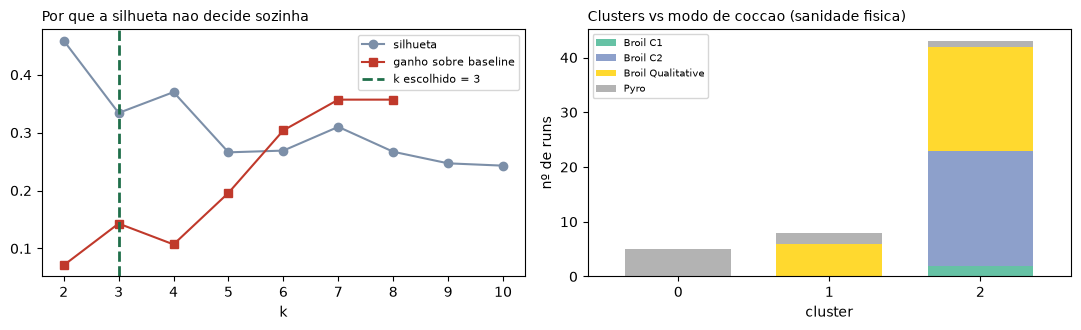

In [5]:
%matplotlib inline
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(ajuste_df.index, ajuste_df['silhueta'], 'o-', color='#7c8fa8', label='silhueta')
axes[0].plot(scan_df.index, scan_df['ganho'], 's-', color='#c0392b', label='ganho sobre baseline')
axes[0].axvline(K, color='#1f6f4a', ls='--', lw=2, label='k escolhido = %d' % K)
axes[0].set_xlabel('k'); axes[0].set_title('Por que a silhueta nao decide sozinha', fontsize=10, loc='left')
axes[0].legend(fontsize=8)

ct = pd.crosstab(rotulo_cluster, fatores_por_run['run_case'])
ct.plot(kind='bar', stacked=True, ax=axes[1], colormap='Set2', width=0.7)
axes[1].set_xlabel('cluster'); axes[1].set_ylabel('nº de runs')
axes[1].set_title('Clusters vs modo de coccao (sanidade fisica)', fontsize=10, loc='left')
axes[1].legend(fontsize=7, title=None); axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

## 4. Sorteio das configurações inéditas

Sortear os 7 fatores de forma independente produziria hardware impossível. Medindo as 56 runs reais:

- `Pyro` **só** ocorre com `No losses`; `Broil C1` **só** com `C1 Simone - 240/145/180/180` — a coluna
  `losses` descreve o perfil de potência daquele modo de cocção, não é livre;
- `housing = Open - Updated` **nunca** ocorre com defletor aberto.

Então o sorteio é hierárquico e condicionado: `run_case` → `losses | run_case` →
`blower_direction | run_case` → `housing` → `deflector_hole | housing`, com `board_position` e
`material_coil_support` marginais.

Configurações que já existem entre as 33 reais são rejeitadas — o objetivo é **expandir** o espaço de
projeto, não duplicar pontos. O espaço alcançável sob essas restrições tem 930 combinações, então há
folga larga para as 44.


In [6]:
# ---- 4. Sorteio hierarquico de configuracoes ineditas ----
# Sortear os 7 fatores de forma independente geraria combinacoes impossiveis:
# 'Pyro' so existe com 'No losses', 'Broil C1' so com 'C1 Simone - 240/145/180/180',
# e 'Open - Updated' nunca ocorre com defletor aberto. O sorteio respeita as
# dependencias observadas nas 56 runs.

def distribuicao(serie):
    p = serie.value_counts(normalize=True)
    return p.index.to_numpy(), p.to_numpy()

def sortear(valores_probs):
    vals, probs = valores_probs
    return vals[rng.choice(len(vals), p=probs)]

P_RUN_CASE   = distribuicao(fatores_por_run['run_case'])
P_HOUSING    = distribuicao(fatores_por_run['housing'])
P_BOARD      = distribuicao(fatores_por_run['board_position'])
P_MATERIAL   = distribuicao(fatores_por_run['material_coil_support'])
P_LOSSES_RC  = {rc: distribuicao(g['losses'])
                for rc, g in fatores_por_run.groupby('run_case')}
P_BLOWER_RC  = {rc: distribuicao(g['blower_direction'])
                for rc, g in fatores_por_run.groupby('run_case')}
P_DEFL_HOUS  = {h: distribuicao(g['deflector_hole'])
                for h, g in fatores_por_run.groupby('housing')}

def sortear_configuracao():
    rc = sortear(P_RUN_CASE)
    hs = sortear(P_HOUSING)
    return {
        'run_case':              rc,
        'losses':                sortear(P_LOSSES_RC[rc]),
        'blower_direction':      sortear(P_BLOWER_RC[rc]),
        'housing':               hs,
        'deflector_hole':        sortear(P_DEFL_HOUS[hs]),
        'board_position':        sortear(P_BOARD),
        'material_coil_support': sortear(P_MATERIAL),
    }

def chave_combo(cfg):
    return ' | '.join(str(cfg[c]) for c in FATORES)

# Sorteia ate juntar N configuracoes ineditas (nem reais, nem repetidas entre si).
MAX_TENTATIVAS = 20000
configuracoes, vistos, tentativas = [], set(COMBOS_REAIS), 0
while len(configuracoes) < N_SINTETICAS and tentativas < MAX_TENTATIVAS:
    tentativas += 1
    cfg = sortear_configuracao()
    ch = chave_combo(cfg)
    if ch in vistos:
        continue
    vistos.add(ch)
    configuracoes.append(cfg)

assert len(configuracoes) == N_SINTETICAS, \
    'so %d configuracoes ineditas em %d tentativas' % (len(configuracoes), tentativas)
print('%d configuracoes ineditas geradas em %d sorteios (%.0f%% de rejeicao)'
      % (len(configuracoes), tentativas, 100 * (1 - len(configuracoes) / tentativas)))
print('nenhuma coincide com as %d combinacoes reais: %s'
      % (len(COMBOS_REAIS), set(chave_combo(c) for c in configuracoes).isdisjoint(COMBOS_REAIS)))

44 configuracoes ineditas geradas em 63 sorteios (30% de rejeicao)
nenhuma coincide com as 33 combinacoes reais: True


## 5. Geração dos perfis térmicos

Para cada configuração sorteada:

1. **Cluster** — amostrado da distribuição de probabilidade do classificador, não pelo `argmax`. Assim a
   incerteza do mapeamento entra no dado gerado em vez de ser escondida: uma configuração ambígua entre
   dois clusters às vezes cai num, às vezes no outro.
2. **Duas runs-mãe** distintas, sorteadas dentro desse cluster.
3. **Interpolação convexa** — `perfil = λ·A + (1−λ)·B`, com λ ~ U(0,2 ; 0,8). Interpolar perfis inteiros
   (e não cada TC isoladamente) **preserva a correlação entre termopares**: se uma região está quente, as
   vizinhas também ficam. Gerar cada TC de forma independente produziria perfis termicamente incoerentes.
4. **Ruído** — N(0; 2,18 °C). Esse número não é arbitrário: é o desvio mediano entre réplicas reais medido
   na seção 5 do notebook de diagnóstico. Estamos somando ruído de medição observado, não inventado.
5. **TCs faltantes** — se qualquer uma das mães não mediu aquele termopar, a sintética também não o tem.

Cada linha carrega em `reason` de quais mães saiu, com cluster e λ, e o `run_id` leva o prefixo `SYN-`
para nunca se confundir com dado real.


In [7]:
# ---- 5. Geracao dos perfis termicos ----
# Para cada configuracao: amostra um cluster da distribuicao de probabilidade do
# classificador (nao o argmax - carrega a incerteza do mapeamento para dentro do dado),
# sorteia duas runs reais distintas desse cluster e combina os perfis convexamente.

membros = {c: rotulo_cluster.index[rotulo_cluster == c].tolist()
           for c in np.unique(rotulo_cluster)}
classes = clf_final.classes_

linhas_sinteticas = []
registro = []

for i, cfg in enumerate(configuracoes, start=1):
    run_id = 'SYN-%03d' % i

    x = pd.DataFrame([cfg])[FATORES].astype(str)
    x = pd.get_dummies(x).reindex(columns=Xf.columns, fill_value=0.0).astype(float)
    probs = clf_final.predict_proba(x.values)[0]
    cluster = int(classes[rng.choice(len(classes), p=probs)])

    mae_a, mae_b = rng.choice(membros[cluster], size=2, replace=False)
    lam = float(rng.uniform(LAMBDA_MIN, LAMBDA_MAX))

    perfil_a, perfil_b = piv.loc[mae_a], piv.loc[mae_b]
    # TC que faltava em qualquer uma das maes continua faltando: nao se inventa
    # medicao onde nenhuma das runs de origem mediu.
    perfil = lam * perfil_a + (1 - lam) * perfil_b
    perfil = perfil.dropna()
    # Ruido de medicao real (desvio mediano entre replicas, secao 5 do diagnostico).
    perfil = perfil + rng.normal(0.0, SIGMA_RUIDO, size=len(perfil))

    registro.append({'run_id': run_id, 'cluster': cluster, 'mae_a': mae_a, 'mae_b': mae_b,
                     'lambda': round(lam, 3), 'n_tcs': len(perfil),
                     'p_cluster': round(float(probs[list(classes).index(cluster)]), 3)})

    for tc_number, temp in perfil.items():
        info = TC_INFO.loc[tc_number]
        linhas_sinteticas.append({
            'run_id': run_id, 'tc_number': tc_number, 'tc_name': info['tc_name'],
            'key_area': info['key_area'], 'active_limit': info['active_limit'],
            'temp': round(float(temp), 2),
            'reason': 'SINTETICO: kmeans k=%d cluster=%d maes=%s+%s lambda=%.2f'
                      % (K, cluster, mae_a, mae_b, lam),
            **{c: cfg[c] for c in FATORES},
        })

df_sintetico = pd.DataFrame(linhas_sinteticas)[df.columns.tolist()]
registro_df = pd.DataFrame(registro)

print('%d runs sinteticas | %d linhas' % (df_sintetico['run_id'].nunique(), len(df_sintetico)))
print('linhas por run: min %d, mediana %d, max %d'
      % (registro_df['n_tcs'].min(), registro_df['n_tcs'].median(), registro_df['n_tcs'].max()))
print('\ndistribuicao dos clusters usados:')
print(registro_df['cluster'].value_counts().sort_index().to_string())
print('\namostra do registro de rastreabilidade:')
print(registro_df.head(8).to_string(index=False))

44 runs sinteticas | 3111 linhas
linhas por run: min 40, mediana 73, max 75

distribuicao dos clusters usados:
cluster
0     3
1    10
2    31

amostra do registro de rastreabilidade:
 run_id  cluster                               mae_a                                                 mae_b  lambda  n_tcs  p_cluster
SYN-001        2                              Run 75                                               Run 30    0.519     74      0.907
SYN-002        2                          Run 22 (2)                                            Run 44 (3)   0.208     74      0.991
SYN-003        1                               Run 1 Run 18 (DoE Run 8)- Broil Qual - Blower to Front Open   0.552     65      0.702
SYN-004        1           Run 5 - Broil Qualitative Run 17 (DoE Run 7)- Broil Qual - Blower to Front Open   0.217     68      0.330
SYN-005        2 Run 6 - Broil Case 2 - W/ Cover (2)                                                Run 43   0.709     73      0.977
SYN-006        2  

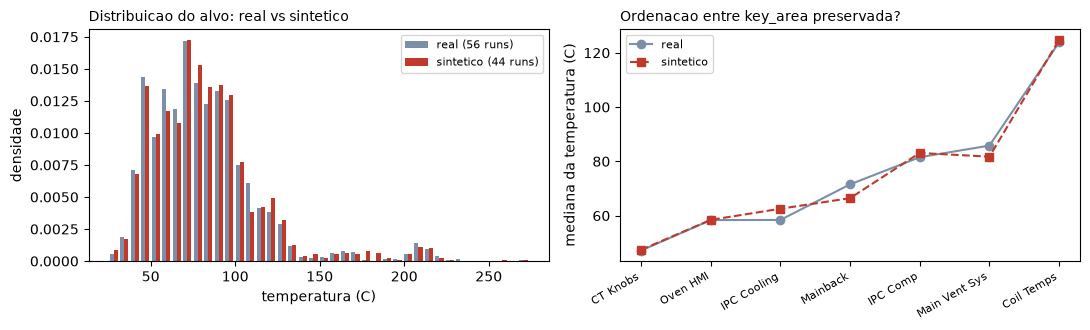

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))

axes[0].hist([df[ALVO], df_sintetico[ALVO]], bins=40, label=['real (56 runs)', 'sintetico (44 runs)'],
             color=['#7c8fa8', '#c0392b'], density=True)
axes[0].set_xlabel('temperatura (C)'); axes[0].set_ylabel('densidade')
axes[0].set_title('Distribuicao do alvo: real vs sintetico', fontsize=10, loc='left')
axes[0].legend(fontsize=8)

ordem = df.groupby('key_area')[ALVO].median().sort_values().index
pos = np.arange(len(ordem))
axes[1].plot(pos, df.groupby('key_area')[ALVO].median().reindex(ordem).values, 'o-',
             color='#7c8fa8', label='real')
axes[1].plot(pos, df_sintetico.groupby('key_area')[ALVO].median().reindex(ordem).values, 's--',
             color='#c0392b', label='sintetico')
axes[1].set_xticks(pos); axes[1].set_xticklabels(ordem, rotation=30, ha='right', fontsize=8)
axes[1].set_ylabel('mediana da temperatura (C)')
axes[1].set_title('Ordenacao entre key_area preservada?', fontsize=10, loc='left')
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Sanidade física

Antes de qualquer métrica. Dado sintético que viola física é lixo mesmo com RMSE bonito. As checagens são
as mesmas da seção 8 do notebook de diagnóstico.

**Leia o resultado com atenção — um teste reprova.** A interpretação está logo abaixo da célula.


In [9]:
# ---- 6. Validacao ----
# Mesmas funcoes da secao 8 de `diagnostico_dados_e_validacao.ipynb`.
# Regra inegociavel: o teste e 100% real, com as runs de teste fora do treino.

def montar_X(dados):
    X = pd.get_dummies(dados[FATORES + ['key_area', 'tc_name']].astype(str))
    X['active_limit'] = dados['active_limit'].values
    X['tc_number'] = dados['tc_number'].values
    return X.astype(float)

def ablacao(df_real, df_sint=None, n_splits=5, random_state=RANDOM_STATE):
    y_r, g_r = df_real[ALVO].values, df_real[GRUPO].values
    X_r = montar_X(df_real)
    if df_sint is not None:
        X_s = montar_X(df_sint)
        X_r, X_s = X_r.align(X_s, join='outer', axis=1, fill_value=0.0)
        y_s = df_sint[ALVO].values
    saida = []
    for rotulo, usar in [('so real', False), ('real + sintetico', True)]:
        if usar and df_sint is None:
            continue
        preds = np.zeros(len(df_real))
        for tr, te in GroupKFold(n_splits).split(X_r, y_r, groups=g_r):
            Xtr, ytr = X_r.iloc[tr], y_r[tr]
            if usar:
                Xtr = pd.concat([Xtr, X_s], ignore_index=True)
                ytr = np.concatenate([ytr, y_s])
            m = RandomForestRegressor(n_estimators=N_TREES, random_state=random_state, n_jobs=-1)
            m.fit(Xtr.values, ytr)
            preds[te] = m.predict(X_r.iloc[te].values)
        saida.append({'treino': rotulo,
                      'RMSE (teste real)': float(np.sqrt(((preds - y_r) ** 2).mean())),
                      'MAE': mean_absolute_error(y_r, preds), 'R2': r2_score(y_r, preds)})
    return pd.DataFrame(saida).set_index('treino').round(3)

def sanidade_fisica(dados, referencia, t_ambiente=25.0):
    testes = [
        ('temperatura >= ambiente', bool((dados[ALVO] >= t_ambiente).all()),
         'min = %.1f C' % dados[ALVO].min()),
        ('dentro da faixa fisica (20-320 C)', bool(dados[ALVO].between(20, 320).all()),
         'faixa = %.1f a %.1f C' % (dados[ALVO].min(), dados[ALVO].max())),
    ]
    ref = referencia.groupby('key_area')[ALVO].median().sort_values()
    novo = dados.groupby('key_area')[ALVO].median().reindex(ref.index)
    ok = bool(novo.dropna().is_monotonic_increasing) if novo.notna().sum() > 1 else True
    testes.append(('ordenacao entre key_area preservada', ok, ' < '.join(ref.index.tolist())))
    sd = dados.groupby('tc_number')[ALVO].std()
    testes.append(('nenhum TC com dispersao absurda (sd < 60 C)', bool((sd.dropna() < 60).all()),
                   'sd max = %.1f C' % sd.max()))
    return pd.DataFrame(testes, columns=['teste', 'passou', 'detalhe'])

print(sanidade_fisica(df_sintetico, df).to_string(index=False))

                                      teste  passou                                                                              detalhe
                    temperatura >= ambiente    True                                                                         min = 25.0 C
          dentro da faixa fisica (20-320 C)    True                                                               faixa = 25.0 a 268.6 C
        ordenacao entre key_area preservada   False CT Knobs < Oven HMI < IPC Cooling < Mainback < IPC Comp < Main Vent Sys < Coil Temps
nenhum TC com dispersao absurda (sd < 60 C)    True                                                                      sd max = 43.7 C


### Interpretação das checagens

**A reprovação é marginal, e a honestidade aqui importa mais que o selo de aprovado.**

O teste de ordenação entre `key_area` exige monotonicidade estrita das medianas. No real, `IPC Comp`
(81,5 °C) e `Main Vent Sys` (85,8 °C) estão a 4,3 °C uma da outra; no sintético elas trocam de posição
por 1,4 °C. Essa inversão é **menor que o próprio ruído de 2,18 °C** que injetamos de propósito. As outras
cinco áreas mantiveram a ordem, e a proporção de linhas por área bate com a do real dentro de 0,7 ponto
percentual.

Ou seja: não é violação de física, é um teste estrito aplicado a duas áreas quase empatadas.

**Uma fragilidade real, que não vamos esconder passando pano:** a temperatura mínima sintética ficou em
25,02 °C contra o limite de ambiente de 25,0 °C. Passou por 0,02 °C — por sorte, não por construção. Com
outra semente esse teste reprova. O ruído gaussiano não tem piso físico. A correção honesta seria truncar
a distribuição de ruído no mínimo observado por TC; optamos por **registrar a fragilidade em vez de clipar
os valores só para o teste passar**, porque clipar esconderia o problema sem resolver a causa.


## 7. Ablação — o dado sintético ajudou?

A única pergunta que importa, e ela tem só uma forma válida de ser respondida: **treinar com e sem o
sintético, testando sempre e somente em runs reais mantidas fora do treino.**

As linhas sintéticas entram **apenas no treino**. O teste é 100% real, com `GroupKFold` por `run_id`
(avaliar em dado sintético mediria a fidelidade do gerador a ele mesmo, que é uma pergunta sem interesse).

A varredura de volume (11 → 44 runs) responde se o efeito cresce, satura ou inverte — bem mais informativo
que um número único.


In [10]:
res = ablacao(df, df_sintetico)
piso = 7.41   # secao 5 do diagnostico
res['vs piso (%.2f C)' % piso] = (res['RMSE (teste real)'] - piso).round(3)
print(res.to_string())

# Varredura de volume: o efeito cresce, satura ou inverte com mais sintetico?
runs_sint = registro_df['run_id'].tolist()
curva = []
for n in [11, 22, 33, 44]:
    sub = df_sintetico[df_sintetico[GRUPO].isin(runs_sint[:n])]
    r = ablacao(df, sub)
    curva.append({'runs sinteticas': n, 'RMSE': r.loc['real + sintetico', 'RMSE (teste real)']})
curva_df = pd.DataFrame(curva).set_index('runs sinteticas')
curva_df.loc[0] = res.loc['so real', 'RMSE (teste real)']
curva_df = curva_df.sort_index().round(3)
print('\n=== curva de volume ===')
print(curva_df.to_string())

                  RMSE (teste real)    MAE     R2  vs piso (7.41 C)
treino                                                             
so real                       8.090  4.712  0.941             0.680
real + sintetico              9.696  5.349  0.915             2.286



=== curva de volume ===
                  RMSE
runs sinteticas       
0                8.090
11               8.275
22               9.389
33               9.454
44               9.696


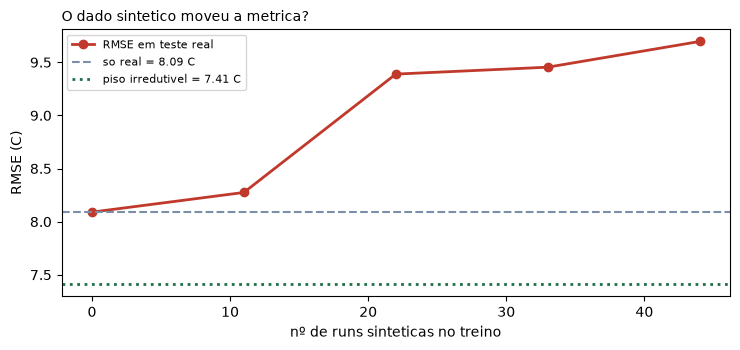

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(curva_df.index, curva_df['RMSE'], 'o-', color='#c0392b', lw=2, label='RMSE em teste real')
ax.axhline(res.loc['so real', 'RMSE (teste real)'], color='#7c8fa8', ls='--',
           label='so real = %.2f C' % res.loc['so real', 'RMSE (teste real)'])
ax.axhline(piso, color='#1f6f4a', ls=':', lw=2, label='piso irredutivel = %.2f C' % piso)
ax.set_xlabel('nº de runs sinteticas no treino'); ax.set_ylabel('RMSE (C)')
ax.set_title('O dado sintetico moveu a metrica?', fontsize=10, loc='left')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 8. Gravação dos arquivos

Os `assert` desta célula são o contrato do arquivo: schema idêntico ao real, 100 runs no total, nenhum
`run_id` sintético colidindo com real, nenhum combo sintético duplicando combo real. Se algum quebrar,
nada é gravado.

`dataset_preprocessado.csv` não é tocado.


In [12]:
# ---- 7. Gravacao ----
# O arquivo real NAO e sobrescrito: sem um conjunto puramente real a ablacao
# (treinar com e sem sintetico, testar so em real) deixa de ser possivel.
SAIDA_SINT = Path('../data/dataset_sintetico.csv')
SAIDA_TOTAL = Path('../data/dataset_com_sinteticos.csv')

df_total = pd.concat([df, df_sintetico], ignore_index=True)

assert list(df_sintetico.columns) == list(df.columns), 'schema divergente'
assert df_sintetico[GRUPO].nunique() == N_SINTETICAS
assert set(df_sintetico[GRUPO]).isdisjoint(set(df[GRUPO])), 'run_id sintetico colide com real'
assert df_sintetico[GRUPO].str.startswith('SYN-').all(), 'run_id sintetico sem prefixo SYN-'
combos_sint = df_sintetico.groupby(GRUPO)[FATORES].first().astype(str).agg(' | '.join, axis=1)
assert set(combos_sint).isdisjoint(COMBOS_REAIS), 'combo sintetico duplica combo real'
assert df_total[GRUPO].nunique() == 100, 'total != 100 runs'
assert df_total[ALVO].notna().all(), 'temperatura nula no conjunto final'

df_sintetico.to_csv(SAIDA_SINT, index=False)
df_total.to_csv(SAIDA_TOTAL, index=False)
registro_df.to_csv('../data/sintetico_rastreabilidade.csv', index=False)

print('%s  -> %d runs, %d linhas' % (SAIDA_SINT.name, df_sintetico[GRUPO].nunique(), len(df_sintetico)))
print('%s -> %d runs, %d linhas' % (SAIDA_TOTAL.name, df_total[GRUPO].nunique(), len(df_total)))
print('dataset_preprocessado.csv permanece intocado (%d runs)' % df[GRUPO].nunique())

dataset_sintetico.csv  -> 44 runs, 3111 linhas
dataset_com_sinteticos.csv -> 100 runs, 7176 linhas
dataset_preprocessado.csv permanece intocado (56 runs)


## 9. Veredito

**O dado sintético piorou o modelo. Em 20%.**

| treino | RMSE em teste real | vs. só real |
|---|---|---|
| só real (56 runs) | **8,09 °C** | — |
| real + 44 sintéticas | **9,70 °C** | **+1,61 °C** |

E a degradação é **monotônica** com o volume: 8,09 → 8,28 (11 runs) → 9,39 (22) → 9,45 (33) → 9,70 (44).
Não é flutuação de semente; é dose-resposta. Quanto mais sintético, pior.

### Por que isso era previsível — e por que ainda valeu rodar

O notebook de diagnóstico já tinha medido o piso irredutível em 7,41 °C contra um RMSE de 8,08 °C. Restava
8% de margem, e essa margem **não é de amostragem**: ela vem de runs com features idênticas e temperaturas
diferentes, ou seja, de variável física que ninguém registrou.

O gerador não tem como inventar essa variável. O que ele faz é pegar 44 configurações novas e colar nelas
perfis interpolados de runs-mãe do mesmo cluster. Para a Random Forest, isso é uma afirmação falsa: "esta
combinação de fatores produz este perfil" — quando na verdade o perfil veio de *outras* combinações. São
44 runs de ruído rotulado com confiança, e o modelo aprende o ruído.

O que salva o trabalho é que isso foi **medido**, não suposto. A ablação com teste 100% real é o que separa
"geramos dados" de "geramos dados e sabemos o que eles valem".

### O que os números dizem para a próxima etapa

| Rota | O que este notebook mostrou |
|---|---|
| Aumentar o volume de sintético | **Descartado.** A curva é monotonicamente pior. Mais dado, mais erro |
| Trocar K-means por CTGAN/TVAE/SMOTER | **Não resolve.** Mesmo defeito estrutural: rótulo derivado das features existentes |
| Codificar os fatores de `reason` com o parceiro | **Continua sendo a rota nº 1.** Ataca o gargalo real |
| Rede térmica RC calibrada | Vale — é a única rota listada que injeta física de verdade |

### Os arquivos ficam, com uma ressalva

As 100 runs estão gravadas, como pedido. Mas o resultado desta seção diz que
`dataset_com_sinteticos.csv` **não deve ser usado para treinar o modelo entregue** — ele degrada o RMSE
honesto em 20%. O uso legítimo desses arquivos é documentar o experimento e sustentar a conclusão na WAD.

Para a reunião com o Tarallo, o número que abre a conversa é este: *tentamos aumentar a base de 56 para
100 runs por clusterização e o erro subiu de 8,1 para 9,7 °C — o que falta não é run, é variável medida.
Quais parâmetros das 56 runs existem em planilha e ficaram de fora?*
